In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
color = sns.color_palette()
pd.set_option('display.precision', 3)

In [4]:
df = pd.read_csv('winequality-red.csv', sep=';')
display(df.head())
print("数据的维度:", df.shape)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.997,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5


数据的维度: (1599, 12)


In [5]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000
mean,8.320,0.528,0.271,2.539,0.087,15.875,46.468,0.997,3.311,0.658,10.423,5.636
std,1.741,0.179,0.195,1.410,0.047,10.460,32.895,0.002,0.154,0.170,1.066,0.808
min,4.600,0.120,0.000,0.900,0.012,1.000,6.000,0.990,2.740,0.330,8.400,3.000
25%,7.100,0.390,0.090,1.900,0.070,7.000,22.000,0.996,3.210,0.550,9.500,5.000
50%,7.900,0.520,0.260,2.200,0.079,14.000,38.000,0.997,3.310,0.620,10.200,6.000
75%,9.200,0.640,0.420,2.600,0.090,21.000,62.000,0.998,3.400,0.730,11.100,6.000
max,15.900,1.580,1.000,15.500,0.611,72.000,289.000,1.004,4.010,2.000,14.900,8.000


In [6]:
print('quality的取值个数:', df['quality'].nunique())
print('quality的取值:', df['quality'].unique())
print(df.groupby('quality').mean())

quality的取值个数: 6
quality的取值: [5 6 7 4 8 3]
         fixed acidity  volatile acidity  citric acid  residual sugar  \
quality                                                                 
3                8.360             0.885        0.171           2.635   
4                7.779             0.694        0.174           2.694   
5                8.167             0.577        0.244           2.529   
6                8.347             0.497        0.274           2.477   
7                8.872             0.404        0.375           2.721   
8                8.567             0.423        0.391           2.578   

         chlorides  free sulfur dioxide  total sulfur dioxide  density     pH  \
quality                                                                         
3            0.123               11.000                24.900    0.997  3.398   
4            0.091               12.264                36.245    0.997  3.382   
5            0.093               16.984          

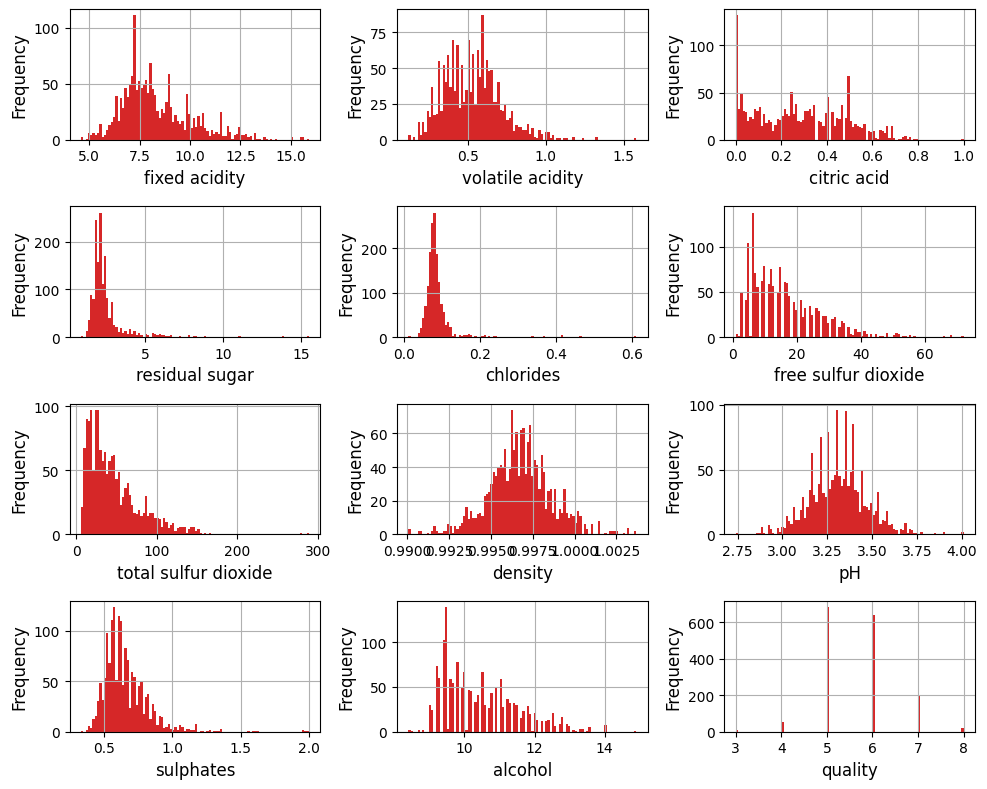

In [7]:
color = sns.color_palette()
column = df.columns.tolist()
fig = plt.figure(figsize=(10, 8))
for i in range(12):
    plt.subplot(4, 3, i + 1)
    df[column[i]].hist(bins=100, color=color[3])
    plt.xlabel(column[i], fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
plt.tight_layout()

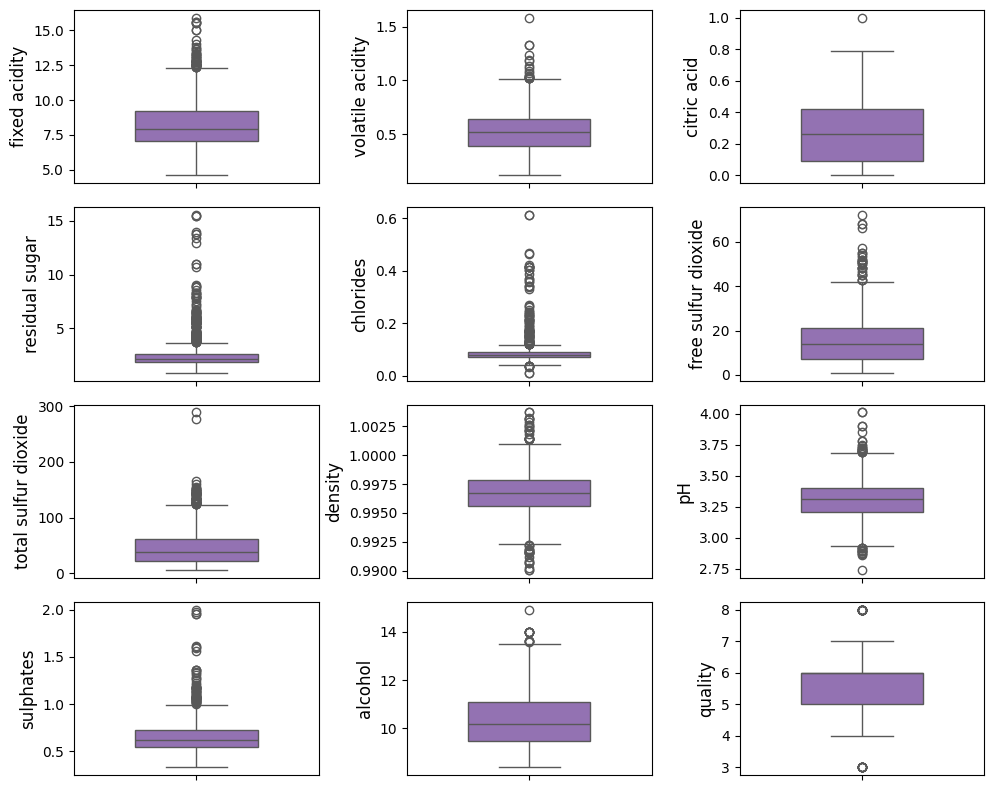

In [8]:
fig = plt.figure(figsize=(10, 8))
for i in range(12):
    plt.subplot(4, 3, i + 1)
    sns.boxplot(df[column[i]], orient='v', width=0.5, color=color[4])
    plt.ylabel(column[i], fontsize=12)
plt.tight_layout()

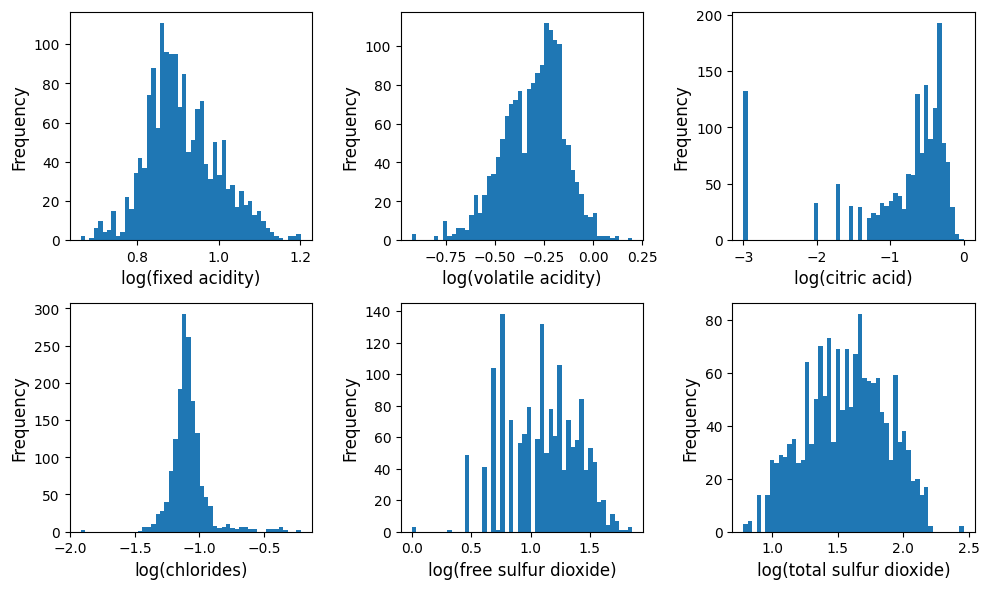

In [9]:
acidityfeat = ['fixed acidity', 'volatile acidity', 'citric acid', 'chlorides',
               'free sulfur dioxide', 'total sulfur dioxide', 'pH']
fig = plt.figure(figsize=(10, 6))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    v = np.log10(np.clip(df[acidityfeat[i]].values, a_min=0.001, a_max=None))
    plt.hist(v, bins=50, color=color[0])
    plt.xlabel('log(' + acidityfeat[i] + ')', fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
plt.tight_layout()

In [10]:
df['sweetness'] = pd.cut(df['residual sugar'], bins=[0, 4, 12, 45], labels=['dry', 'semi-dry', 'semi-sweet'])
df.head()


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,sweetness
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5,dry
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.997,3.20,0.68,9.8,5,dry
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0.65,9.8,5,dry
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,0.58,9.8,6,dry
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5,dry


Figure 5


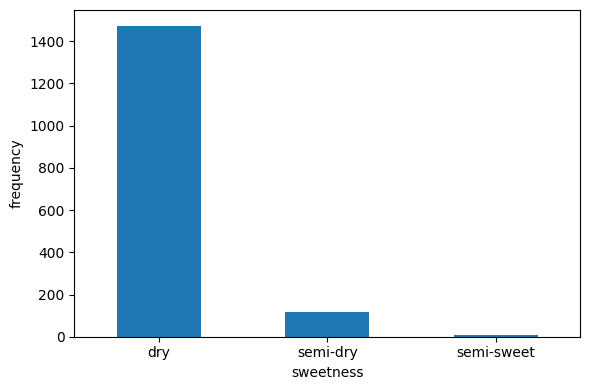

In [11]:
plt.figure(figsize=(6, 4))
df['sweetness'].value_counts().plot(kind='bar', color=color[0])
plt.xticks(rotation=0)
plt.xlabel('sweetness')
plt.ylabel('frequency')
plt.tight_layout()
print("Figure 5")

Figure 7:PhysicoChemioco Properties and Wine Quality by Boxplot


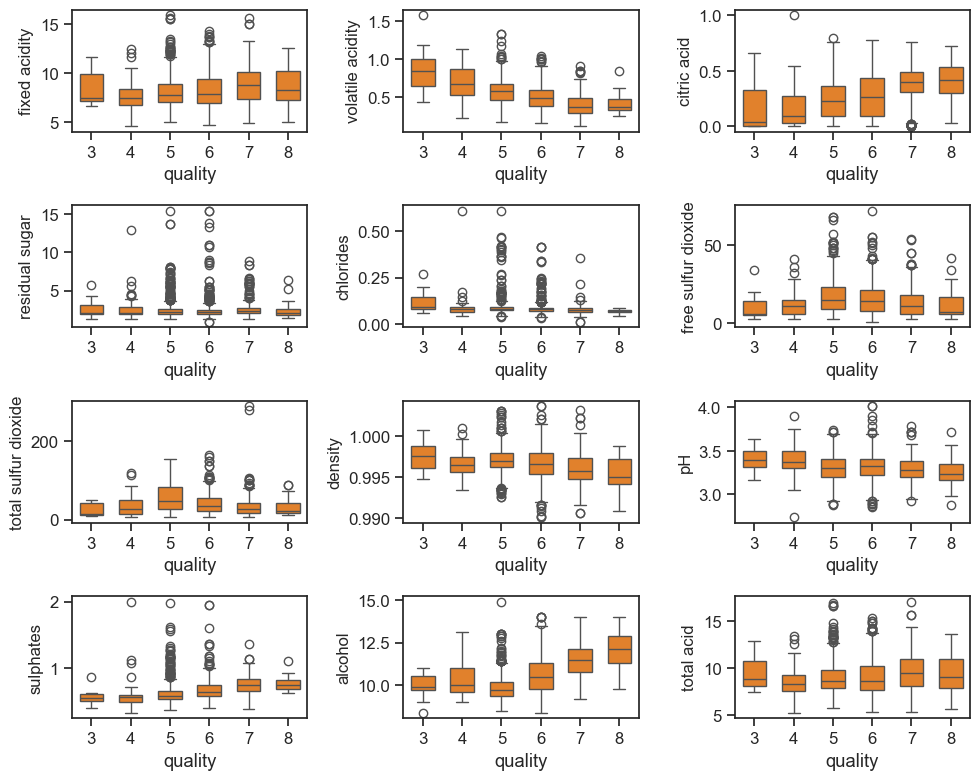

In [12]:
df['total acid'] = df['fixed acidity'] + df['volatile acidity'] + df['citric acid']
columns = df.columns.tolist()
columns.remove('sweetness')
sns.set_style('ticks')
sns.set_context('notebook', font_scale=1.1)
column = columns[0:11] + ['total acid']
plt.figure(figsize=(10, 8))
for i in range(12):
    plt.subplot(4, 3, i + 1)
    sns.boxplot(x='quality', y=column[i], data=df, color=color[1], width=0.6)
    plt.ylabel(column[i], fontsize=12)
plt.tight_layout()
print("Figure 7:PhysicoChemioco Properties and Wine Quality by Boxplot")

(7.0, 16.0)

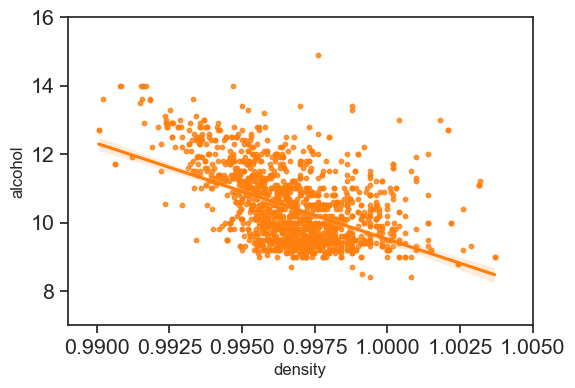

In [13]:
sns.set_style('ticks')
sns.set_context('notebook', font_scale=1.4)
plt.figure(figsize=(6, 4))
sns.regplot(x='density', y='alcohol', data=df, scatter_kws={'s':10}, color=color[1])
plt.xlabel('density', fontsize=12)
plt.ylabel('alcohol', fontsize=12)
plt.xlim(0.989, 1.005)
plt.ylim(7, 16)

In [14]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
sweetness               0
total acid              0
dtype: int64

In [15]:
sweetness = pd.get_dummies(df['sweetness'])
df = pd.concat([df, sweetness], axis=1)
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,sweetness,total acid,dry,semi-dry,semi-sweet
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5,dry,8.10,True,False,False
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.997,3.20,0.68,9.8,5,dry,8.68,True,False,False
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0.65,9.8,5,dry,8.60,True,False,False
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,0.58,9.8,6,dry,12.04,True,False,False
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5,dry,8.10,True,False,False


In [18]:
labels = df['quality']
features = df.drop('quality', axis=1)
from sklearn.model_selection import train_test_split
train_features, test_features, train_labels, test_labels = train_test_split(features, labels, test_size=0.3, random_state=0)
print('训练特征的规模:', train_features.shape)
print('训练标签的规模:', train_labels.shape)
print('测试特征的规模:', test_features.shape)
print('测试标签的规模:', test_labels.shape)

训练特征的规模: (1119, 15)
训练标签的规模: (1119,)
测试特征的规模: (480, 15)
测试标签的规模: (480,)


In [19]:
from sklearn import svm
classifier = svm.SVC(kernel='linear', gamma=0.1)
classifier.fit(train_features, train_labels)
print('训练集的准确率:', classifier.score(train_features, train_labels))
print('测试集的准确率:', classifier.score(test_features, test_labels))

训练集的准确率: 0.5924932975871313
测试集的准确率: 0.6229166666666667
